In [ ]:
# MNIST data 다운로드
from tensorflow import keras
(train_input, train_target), (test_input, test_target) =\
    keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print(train_input.shape, train_target.shape)

(60000, 28, 28) (60000,)


In [ ]:
print(test_input.shape, test_target.shape)

(10000, 28, 28) (10000,)


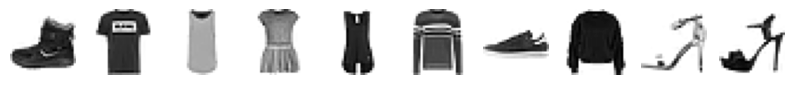

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 10, figsize=(10, 10))
for i in range(10):
    axs[i].imshow(train_input[i], cmap='gray_r')
    axs[i].axis('off')

plt.show()

In [ ]:
# 처음 10개 샘플의 타겟값
print([train_target[i] for i in range(10)])

[9, 0, 0, 3, 0, 2, 7, 2, 5, 5]



패션 MNIST 타겟의 10개 레이블의 의미

0.   티셔츠
1.   바지
2.   스웨터
3.   드레스
4.   코트
5.   샌달
6.   셔츠
7.   스니커즈
8.   가방
9.   앵클 부츠



In [ ]:
# 레이블 당 샘플 개수 확인
import numpy as np
print(np.unique(train_target, return_counts=True))

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]))


In [ ]:
# 0~255 사이의 정숫값을 가지는 이미지의 경우 255로 나누어 0~1 사이의 값으로 정규화
# SGDClassifier는 2차원 입력을 다루지 못하기 때문에 각 샘플을 1차원 배열로 만들어 줌
train_scaled = train_input / 255.0
train_scaled = train_scaled.reshape(-1, 28*28)

In [ ]:
print(train_scaled.shape)

(60000, 784)


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import SGDClassifier

sc = SGDClassifier(loss = 'log_loss', max_iter=5, random_state=42)
scores = cross_validate(sc, train_scaled, train_target, n_jobs=-1)
print(np.mean(scores['test_score']))

0.8194166666666666


패션 MNIS 데이터에 맞게 변형한 로지스틱 회귀 공식

$z_{티셔츠} = w1 \times (픽셀1) + w2 \times (픽셀2) +  \ldots  + w784 \times(픽셀784) + b$

$z_{바지} = w1'  \times (픽셀1) + w2' \times (픽셀2) +  \ldots  + w784' \times(픽셀784) + b'$


**티셔츠를 계산하기 위해 픽셀 784개와 곱하는 가중치 784개와 절편이 바지를 계산하기 위해 픽셀 784개와 곱하는 가중치 784개, 절편과 다르다**

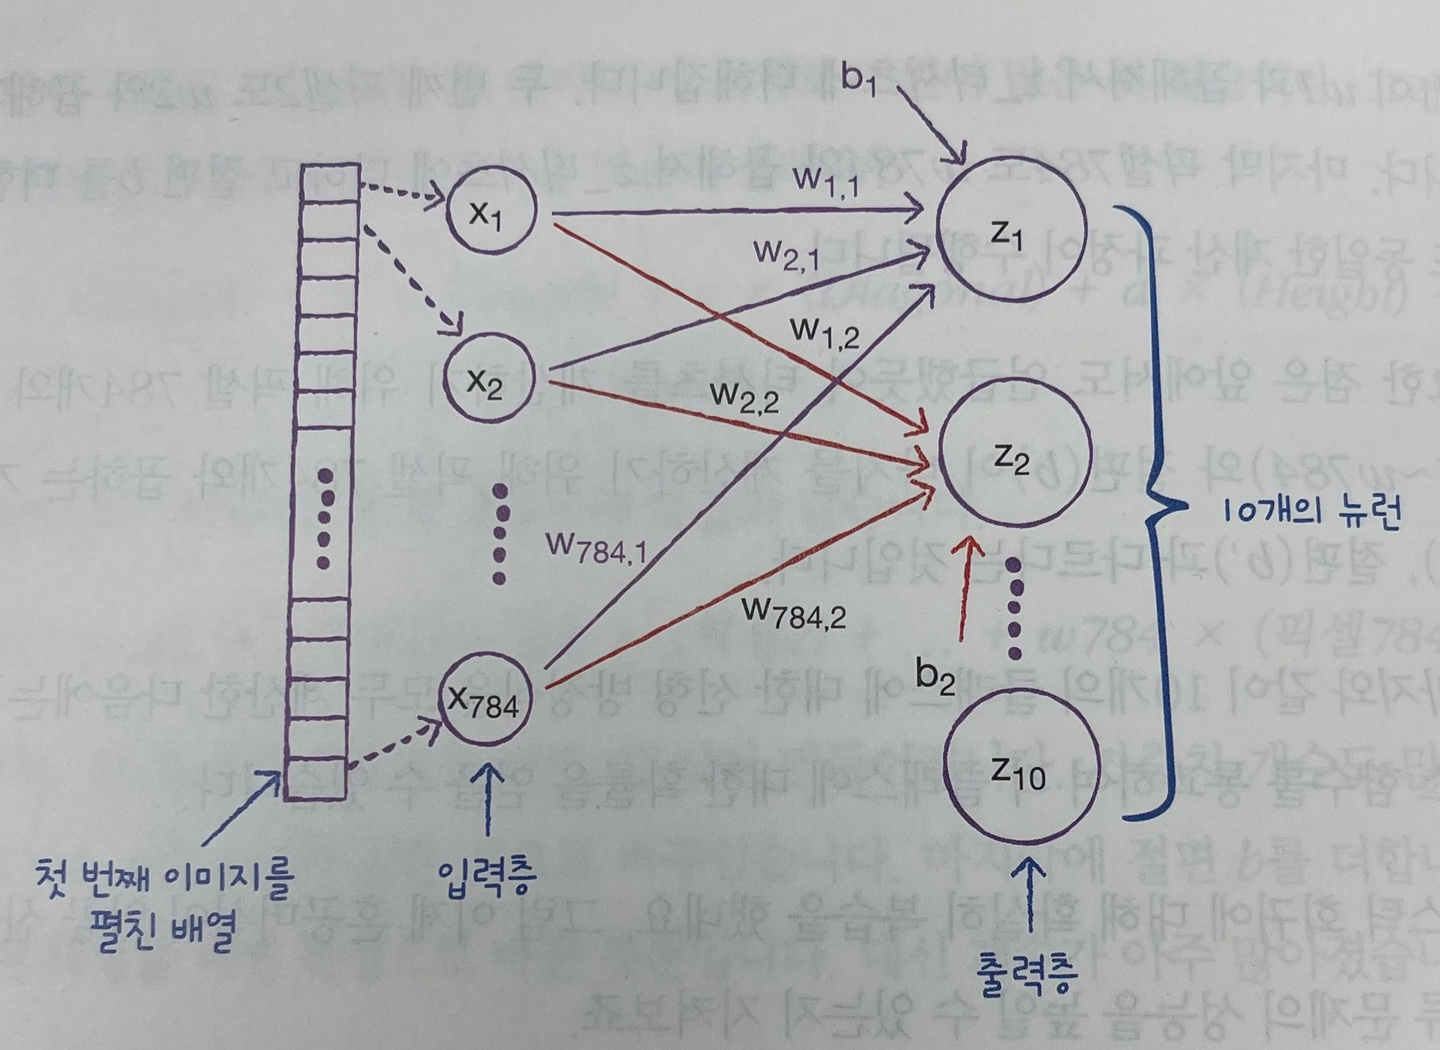

클래스가 총 10개이므로 z_10까지 계산한다.

z_1 ~ z_10을 계싼하고 이를 바탕으로 클래스를 예측하기 때문에 신경망의 최종 값을 만든다는 의미에서 출력층(Output Layer)이라고 부릅니다.

인공신경망에서 z값을 계산하는 단위를 뉴런(Neuron)이라고 부릅니다. 하지만 뉴런에서 일어나는 일은 선형 계산이 전부이다.

이제는 뉴런이란 표현 대신 유닛(Unit)이라고 부르는 사람이 더 많아지고 있다.

픽셀1, 픽셀 2를 x_1, x_2와 같이 바꾸었다.

인공 신경망은 x_1 ~ x_784까지를 입력층(Input Layer)이라고 부른다.

즉 입력층인 픽셀값 자체이고 특별한 계산을 수행하지 않는다.

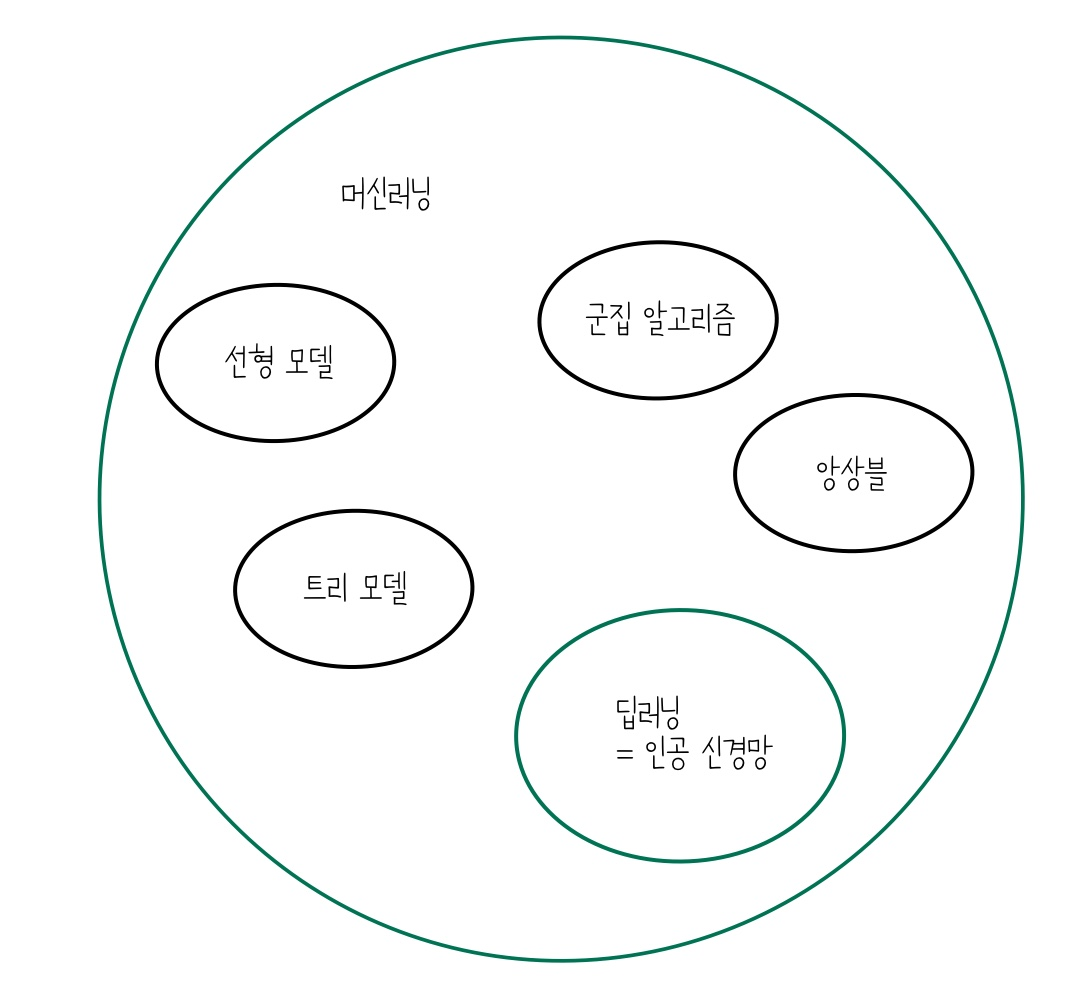

In [10]:
from tensorflow import keras

### 인공 신경망으로 모델 만들기

In [11]:
from sklearn.model_selection import train_test_split

train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)

In [12]:
print(train_scaled.shape, train_target.shape)

(48000, 784) (48000,)


In [13]:
print(val_scaled.shape, val_target.shape)

(12000, 784) (12000,)


In [18]:
dense = keras.layers.Dense(10, activation='softmax', input_shape=(784,))

kears.layers.Dense(뉴런 개수, 뉴런의 출력에 적용할 함수, 입력의 크기)

In [20]:
model = keras.Sequential([dense])

In [21]:
# 인공 신경망으로 패션 아이템 분류하기

model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])

손실 함수 정리

1. 이진 분류 :loss = 'binary_crossentropy'
2. 다중 분류 :loss = 'categorical_crossentropy'

타겟 값을 원-핫 인코딩으로 준비했다면 loss='categorical_crossentropy' 사용

In [22]:
model.fit(train_scaled, train_target, epochs=5)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7367 - loss: 0.7737
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8379 - loss: 0.4830
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8443 - loss: 0.4579
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8485 - loss: 0.4412
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8530 - loss: 0.4328


In [24]:
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8498 - loss: 0.4362


[0.4431699514389038, 0.8493333458900452]

사이킷런 모델


```
모델 -> sc = SGDClassifier(loss='log_loss', max_iter=5)
훈련 -> sc.fit(train_scaled, train_target)
평가 -> sc.score(val_scaled, val_target)
```

케라스 모델
```
        dense = keras.layers.Dense(10, activation='softmax', input_shape=(784,))
모델 -> model = kras.Sequential([dense])
        model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
훈련 -> model.fit(train_scaled, train_target, epochs=5)
평가 -> model.evaluate(val_scaled, val_target)
```
